In [12]:
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.stats.power as smp
from scipy import stats
#from tqdm.notebook import tqdm
from tqdm import tqdm
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.proportion import proportion_confint

**Кейс**  
Применение SPRT анализа в АБ-тесте.  
Была внедрена новая карточка объявлений авто. Основная цель вырастить конверсию в контакт в рамках одной сессии.
АБ-тест закончился и нужно проанализировать  результаты.  

**Есть следующие данные:**  
`cont_conv_A` - конверсия по i-му пользователю в А группе  
`cont_conv_B` - конверсия по j-му пользователю в B группе  
данные в обоих колонках отсортированы по мере поступления в тест, т.е. более ранние строки это пользователи попавшие в тест раньше.

**Задача:** Нужно дать ответ помогло ли изменение карточки авто повысить конверсию?

# SPRT для разницы долей / средних

In [3]:
# Функция для проверки гипотезы о равенстве долей с попощью SPRT
def get_decision_list_sprt_binom(values_A, values_B, alpha = 0.05, beta = 0.2, mde = 0.1):
    ''' Функция проводящая SPRT анализ для пропорций (долей, конверсий)
    values_A - массив значенений коверсии (0, 1) в группе А
    values_B - массив значенений коверсии (0, 1) в группе B
    alpha - уровень статзначимости, который выдерживает SPRT
    beta - уровень ошибки второго рода, который выдерживает SPRT
    mde - абсолютная разница между долями в двух группах, MDE проверяемый в SPRT

    return
    - early_stop_index: индекс на котором SPRT остановился и принял решение.
        Если по результатам всех наблюдений SPRT не смог принять решение возвращается len(data)
    - inference: какая гипотеза была принята по результатам SPRT
    - h0_bound_list: массив границ для принятия решения H0. Длиной early_stop_index
    - h1_bound_list: массив границ для принятия решения H1. Длиной early_stop_index
    - S_list: массив рассчитываемых значений отражающих изменение динамики разницы долей. Длиной early_stop_index
    - cum_diff_list: массив кумулятивной нарастающей разницы между долями в двух группах. Длиной early_stop_index
    '''
    min_len = int(np.mean([len(values_A), len(values_B)]))
    A = math.log(beta/(1 - alpha))
    B = math.log((1 - beta)/alpha)
    p = (values_A.mean() + values_B.mean())/2 # генеральная доля по двум выборкам

    h0_bound_list = []
    h1_bound_list = []
    S_list = []
    cum_diff_list = []

    for i in range(100, min_len):
        p0_i = np.mean(values_A[0:i])
        p1_i = np.mean(values_B[0:i])

        #p = (p0_i + p1_i)/2

        disp = p * (1 - p)
        diff = p1_i - p0_i
        h0_bound = 2 * disp * A / mde
        h1_bound = 2 * disp *  B / mde

        S = (i + 1) * (diff - mde/2)

        h0_bound_list.append(h0_bound)
        h1_bound_list.append(h1_bound)
        S_list.append(S)
        cum_diff_list.append(diff)

        if S < h0_bound:
            return {'early_stop_index':i, 'inference':'Accept H0', 'h0_bound_list': h0_bound_list, 'h1_bound_list': h1_bound_list, 'S_list': S_list, 'cum_diff_list':cum_diff_list}
        if S > h1_bound:
            return {'early_stop_index':i, 'inference':'Accept H1', 'h0_bound_list': h0_bound_list, 'h1_bound_list': h1_bound_list, 'S_list': S_list, 'cum_diff_list':cum_diff_list}
    return {'early_stop_index':i, 'inference':'Continue', 'h0_bound_list': h0_bound_list, 'h1_bound_list': h1_bound_list, 'S_list': S_list, 'cum_diff_list':cum_diff_list}

# Загрузка данных

In [5]:
#Загружаем данные
data = pd.read_csv('E:\Projects\portfolio\causal_inference_method\data\SPRT.csv')
data.head()

,cont_conv_A,cont_conv_B
0,0,0
1,0,0
2,1,0
3,1,0
4,0,0


### Базовый z-тест на пропорцию
Результат: p-value z-test-та

In [6]:
# проведение базового z-test на пропорцию

nobs = [len(data['cont_conv_A']), len(data['cont_conv_B'])]
counts = [np.sum(data['cont_conv_A'] == 1), np.sum(data['cont_conv_B'] == 1)]

stat, pval = proportions_ztest(count=counts, nobs=nobs) # считаем точечную оценку доли для z-теста
print('p-value z-test:', round(pval, 3))

p-value z-test: 0.024


# SPRT анализ
Резвльтат: верная гипотеза по мнению SPRT

Вывод: Accept H1
На каком наблюдении сделан вывод: 15314


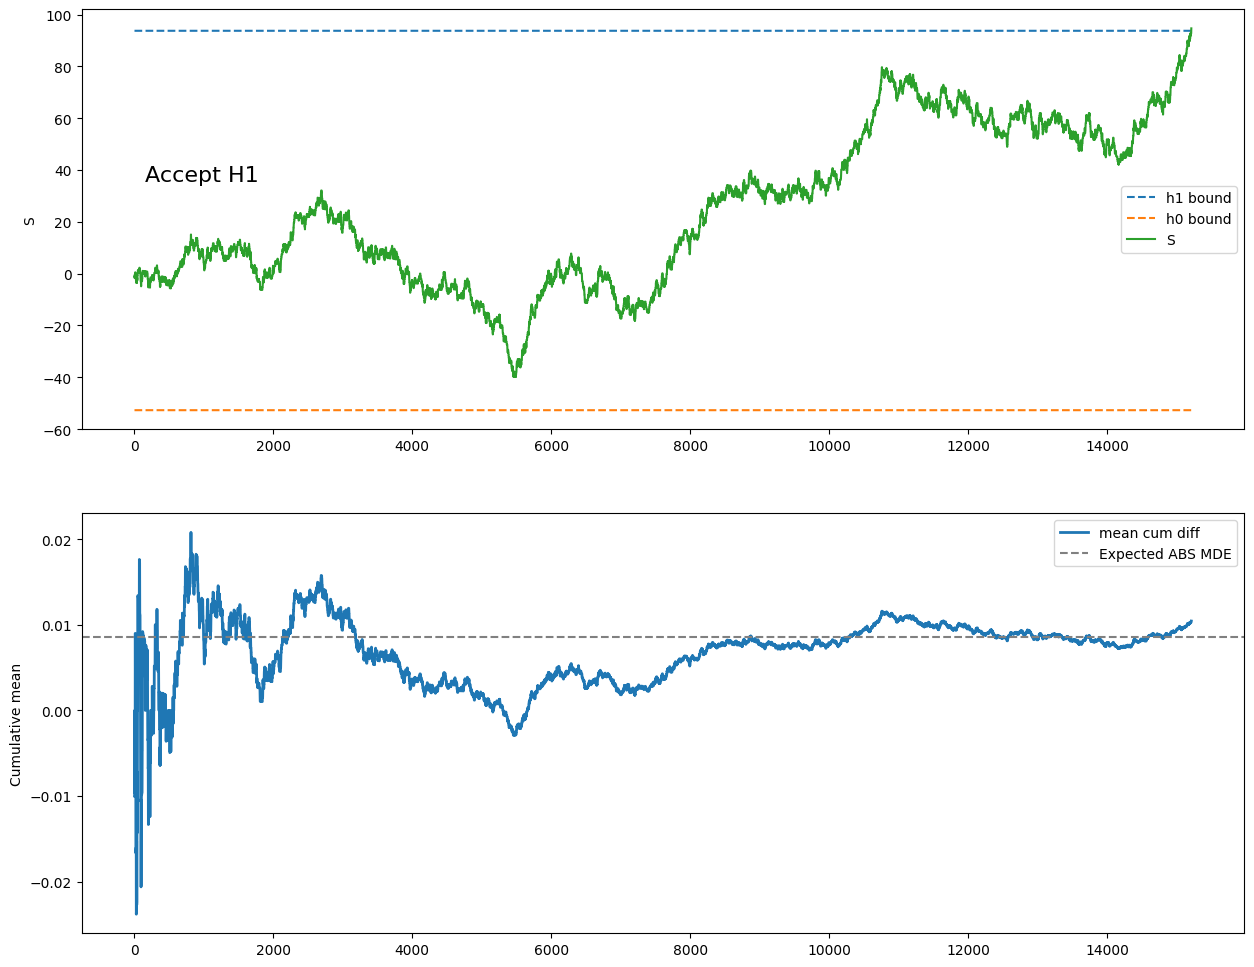

In [7]:
# определим абсолютный MDE для проверки в SPRT
h0 = data['cont_conv_A'].mean()
rel_mde = 0.05
h1 = h0 * (1 + rel_mde)
mde_abs = h0*rel_mde

# проводим SPRT тест на полученных данных
values_A = data['cont_conv_A']
values_B = data['cont_conv_B']
inference_object = get_decision_list_sprt_binom(values_A, values_B, alpha = 0.05, beta = 0.2, mde = mde_abs)
print('Вывод:', inference_object['inference'])
print('На каком наблюдении сделан вывод:', inference_object['early_stop_index'])

fig, axes = plt.subplots(2, figsize=(15,12))

sns.lineplot(ax=axes[0], x = np.arange(1, len(inference_object['h0_bound_list'])+1), y = inference_object['h1_bound_list'], ls = '--', label='h1 bound')
sns.lineplot(ax=axes[0], x = np.arange(1, len(inference_object['h1_bound_list'])+1), y = inference_object['h0_bound_list'], ls = '--', label='h0 bound')
sns.lineplot(ax=axes[0], x = np.arange(1, len(inference_object['S_list'])+1), y = inference_object['S_list'], label='S')
axes[0].set_ylabel(ylabel = "S")
axes[0].text(y = np.quantile(inference_object['S_list'], 0.65), x = len(inference_object['S_list']) * 0.01, s = inference_object['inference'], fontsize = 16)
axes[0].legend()

sns.lineplot(ax=axes[1], x = np.arange(1, len(inference_object['h0_bound_list'])+1), y = inference_object['cum_diff_list'], label='mean cum diff', linewidth=2)
axes[1].axhline(mde_abs, ls='--', color='gray', label = 'Expected ABS MDE')
axes[1].set_ylabel(ylabel = "Cumulative mean")
axes[1].legend()

In [8]:
print('Верная по мнению SPRT гипотеза ->', inference_object['inference'])

Верная по мнению SPRT гипотеза -> Accept H1


## Оценка размера выборки для SPRT (определение в среднем на каком размере выборки мы бы останавливались имея на руках текущие данные)

Определим размер выборки нужный для fixed horizon
- **параметры дизайна**
- относительный MDE = 0.05
- альфа = 0.05
- бета = 0.2
- гипотеза - двусторонняя
- пропорция в выборке 50/50
- исторические данные - данные по конверсии в группе А

Определим среднее время остоновки для АА симуляций
- **Параметры симуляции**
- перед запуском указать np.random.seed(2)
- кол-во симуляций = 300
- для симуляции берутся исторические данные многократно выборки кодом np.random.choice(data['cont_conv_A'], size = len(data['cont_conv_A'])). replace по умолчанию = True
- размер выборок в симуляции = sample size с предыдущего шага

Определим среднее время остоновки для АБ симуляций
- **Параметры симуляции те же**

Оценка мощности методики SPRT на имеющихся данных группы А и Б и относительном MDE = 0.05
- **Параметры симуляции те же**


In [9]:
# определим размер выборки нужный для Fixed Horizon для proportion тест
# за основу берутся данные по группе А из данных теста.


h0 = data['cont_conv_A'].mean()
real_lift = data['cont_conv_B'].mean() - data['cont_conv_A'].mean()
rel_mde = 0.05
h1 = h0 * (1 + rel_mde)
alpha = 0.05
beta = 0.2
mde_abs = h0*rel_mde

cohen_d = 2*math.asin(np.sqrt(h0)) - 2*math.asin(np.sqrt(h0 * (1+rel_mde)))
n_obs = smp.zt_ind_solve_power(effect_size = cohen_d,
                           alpha = alpha,
                           power = 1 - beta,
                           alternative='two-sided')
sample_size = round(n_obs)

print('Размер выборки для Fixed Horizon:', sample_size)
print('mde_absolute:', round(mde_abs, 4))
print('real_lift:', real_lift)

Размер выборки для Fixed Horizon: 31121
mde_absolute: 0.0085
real_lift: 0.00832627716624329


## Симуляция по оценке среднего времени остановки SPRT теста и оценки мощности теста





































































































































































































































































































100%|██████████| 300/300 [03:57<00:00,  1.26it/s]

FP rate = 0.04
Power rate = 0.7366666666666667
Stop index AA: 10696
Stop index AB: 14547


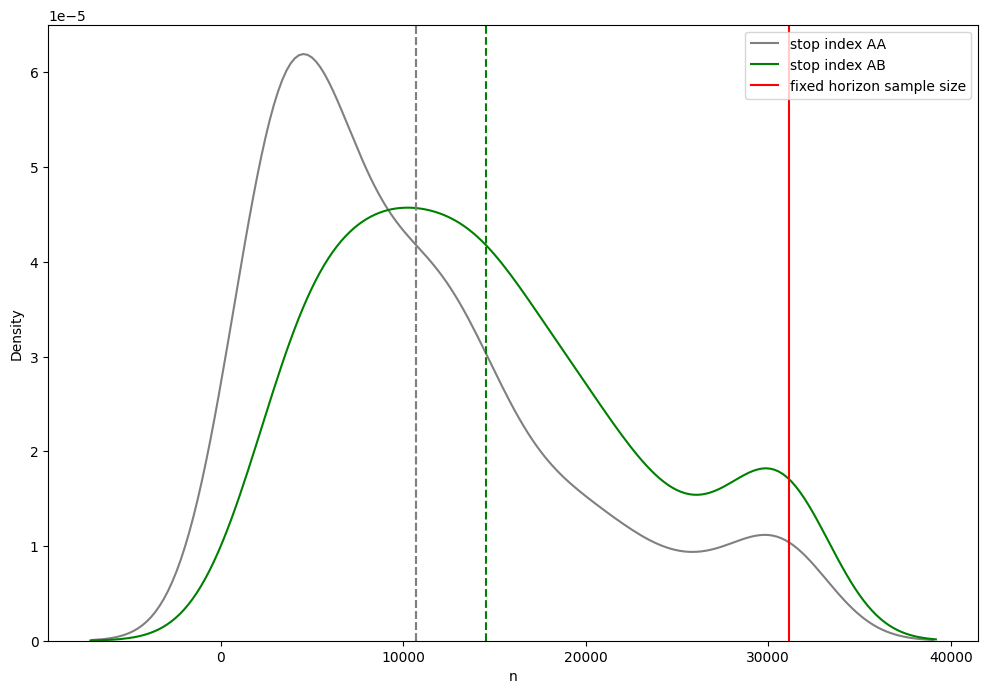

In [13]:
inference_AA_list = []
inference_AB_list = []
stop_index_list_AA = []
stop_index_list_AB = []
diffs_list_AA = []
diffs_list_AB = []
sim_num = 300
np.random.seed(2)
for i in tqdm(range(sim_num)):
    # сгенерируем данные с конверсией с h0 и h1 (с размером выборок с запасом)
    values_A1 = np.random.choice(data['cont_conv_A'], size = sample_size )
    values_A2 = np.random.choice(data['cont_conv_A'], size = sample_size )  # выборка для АА симуляции
    values_B = np.random.choice(data['cont_conv_B'], size = sample_size) # выборка с добавленным эффектом

    inference_object_AA = get_decision_list_sprt_binom(values_A1, values_A2, alpha = 0.05, beta = 0.2, mde = mde_abs)
    inference_object_AB = get_decision_list_sprt_binom(values_A1, values_B, alpha = 0.05, beta = 0.2, mde = mde_abs)

    inference_AA = inference_object_AA['inference']
    inference_AB = inference_object_AB['inference']
    stop_index_AA = inference_object_AA['early_stop_index']
    stop_index_AB = inference_object_AB['early_stop_index']

    inference_AA_list.append(inference_AA)
    inference_AB_list.append(inference_AB)
    stop_index_list_AA.append(stop_index_AA)
    stop_index_list_AB.append(stop_index_AB)

FP = (np.array(inference_AA_list) =='Accept H1').sum() / sim_num
FP_CI = proportion_confint((np.array(inference_AA_list)=='Accept H1').sum() , sim_num, alpha=0.05)
power = (np.array(inference_AB_list) =='Accept H1').sum() / sim_num
power_CI = proportion_confint((np.array(inference_AB_list)=='Accept H1').sum() , sim_num, alpha=0.05)

print('FP rate =', FP)
print('Power rate =', power)
print('Stop index AA:', round(np.mean(stop_index_list_AA)))
print('Stop index AB:', round(np.mean(stop_index_list_AB)))

# распределение времени остановки теста на конверсии с относительным MDE 5%
plt.figure(figsize = (12, 8))
sns.kdeplot(stop_index_list_AA, label = 'stop index AA', color = 'grey')
sns.kdeplot(stop_index_list_AB, label = 'stop index AB', color = 'green')
plt.axvline(x = np.mean(stop_index_list_AA), ls = '--', color = 'grey')
plt.xlabel('n')
plt.axvline(x = np.mean(stop_index_list_AB), ls = '--', color = 'green')
plt.axvline(x = sample_size, label = 'fixed horizon sample size', color = 'red')
plt.axvline(x = np.mean(stop_index_list_AA), ls = '--', color = 'grey')
plt.legend()

In [14]:
print('Среднее время остановки SPRT теста для АА-варианта =', round(np.mean(stop_index_list_AA)))
print('Среднее время остановки SPRT теста для АБ-варианта =', round(np.mean(stop_index_list_AB)))
print('Оценка мощности SPRT теста', power)

Среднее время остановки SPRT теста для АА-варианта = 10696
Среднее время остановки SPRT теста для АБ-варианта = 14547
Оценка мощности SPRT теста 0.7366666666666667
